# Validate linear summation (metamodel vs dynamic)

Compare offshore-driven **dynamic SnapWave** to the **reconstructed metamodel**.

- **`mm.reconstruct(..., spectral=True)`** — partitions ``0``–``3`` per goal, wavespectra linear sum (validation vs dynamic).
- **`mm.reconstruct(..., spectral=False)`** — bulk partition ``-1`` per goal, same wavespectra sum.

Bulk reconstruction output is **`hs`, `tp`, `dir` only** (`spr` is used inside
spectra construction but not returned as a bulk stat). Comparison cells below use
``[["hs", "tp", "dir"]]`` for that reason.

**Prerequisites**

1. Models fitted — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run — `08_Dynamic_Cases_Generation.ipynb` → joined NetCDF

Use `recompute=True` in `mm.reconstruct` after retraining models. Validation loads saved models only (no refitting).

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.model import metamodel as mm
from utils.evaluation import validation as val
from utils.config import SIMULATIONS, resolve


## Configuration

In [2]:
period = "2020-07"
offshore_name = "WHACS"
mda_n = 450  # must match a fitted mda_candidates entry
pca_variance = {"hs": 0.99, "dir": 0.99}  # or 0.99, or {"hs": 0.99, "dir": 0.95}

# Site subset — isobath depth, mesh polygon, buoy id, or umbrella
sites = ["buoy_Aunuu_Buoy"]  # e.g. "10m", "buoy", ["10m", "buoy_Apolima_Buoy"]

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_fullaso.nc"
)

print(f"period       : {period}")
print(f"mda_n        : {mda_n}")
print(f"sites        : {sites}")
print(f"dynamic path : {dynamic_path}")

period       : 2020-07
mda_n        : 450
sites        : ['buoy_Aunuu_Buoy']
dynamic path : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_fullaso.nc


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)
print(f"common model sites: {len(mm.common_model_sites())}")

common model sites: 477


## 2 · Reconstruct metamodel (spectral)

In [4]:
metamodel = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)
metamodel

2026-07-02 08:04:13,170 - Samoa.metamodel - INFO - Reconstruct time='2020-07' n=450 goals=['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11'] partitions=[-1] sites=1
INFO:ExactGPInterpolation:Preprocessing dataset for prediction
INFO:ExactGPInterpolation:Checking for NaNs in subset data
INFO:ExactGPInterpolation:Preprocessing subset data
INFO:ExactGPInterpolation:Normalizing subset data
INFO:ExactGPInterpolation:Proposed max custom scaler for tp is lower than datapoint
INFO:ExactGPInterpolation:Proposed max custom scaler for spr is lower than datapoint
INFO:ExactGPInterpolation:Proposed min custom scaler for dir_v is bigger than datapoint
INFO:ExactGPInterpolation:Subset data preprocessed successfully
INFO:ExactGPInterpolation:Predicting target variable: hs__PC1
INFO:ExactGPInterpolation:Predicting target variable: hs__PC2
INFO:ExactGPInterpolation:Predicting target variable: hs__PC3
INFO:ExactGPInterpolation:Predicting target variable: hs__PC4
INFO:ExactGPInterpolation:Predictin

<xarray.Dataset> Size: 21kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-07-01 ... 2020-07-31T23:00:00
  * sites           (sites) <U24 96B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 28B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -70.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float64 6kB 1.837 1.829 1.822 ... 2.338 2.328
    tp              (time, sites) float32 3kB 10.84 10.84 10.84 ... 8.685 8.597
    dir             (time, sites) float64 6kB 120.5 120.6 120.6 ... 137.8 138.1
Attributes:
    globwave_name:          significant_wave_height
    long_name:              Significant height of wind and swell waves
    standard_name:          sea_surface_wave_significant_height
    units:                  m
    valid_max:              32000
    valid_min:              0
    coverage_content_type:  modelResult
    mesh:                   SMC

## 3 · Load dynamic reference

In [5]:
dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids).load()
dynamic

<xarray.Dataset> Size: 15kB
Dimensions:         (time: 744, sites: 1)
Coordinates:
  * time            (time) datetime64[ns] 6kB 2020-07-01 ... 2020-07-31T23:00:00
  * sites           (sites) <U24 96B 'buoy_Aunuu_Buoy'
    site_source     (sites) <U7 28B 'buoy'
    site_label      (sites) <U5 20B 'waves'
    site_depth      (sites) float64 8B -70.0
    site_longitude  (sites) float64 8B -170.5
    site_latitude   (sites) float64 8B -14.27
Data variables:
    hs              (time, sites) float32 3kB 1.759 1.752 1.745 ... 2.159 2.147
    tp              (time, sites) float32 3kB 9.495 9.513 9.52 ... 8.991 9.729
    dir             (time, sites) float32 3kB 117.6 117.9 118.3 ... 131.8 131.9
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

## 4 · Compare

In [7]:
result = val.compare(
    metamodel[["hs", "tp", "dir"]],
    dynamic[["hs", "tp", "dir"]],
    estimate_label="Linear summation",
    reference_label="Dynamic SnapWave",
)
result.metrics

2026-07-02 08:04:52,173 - Samoa.validation - INFO - Computed 3 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label
0,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,744,0.131802,0.157477,0.868978,Linear summation,Dynamic SnapWave
1,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,744,-0.177531,1.215449,0.677606,Linear summation,Dynamic SnapWave
2,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,744,2.224795,6.188794,0.816643,Linear summation,Dynamic SnapWave


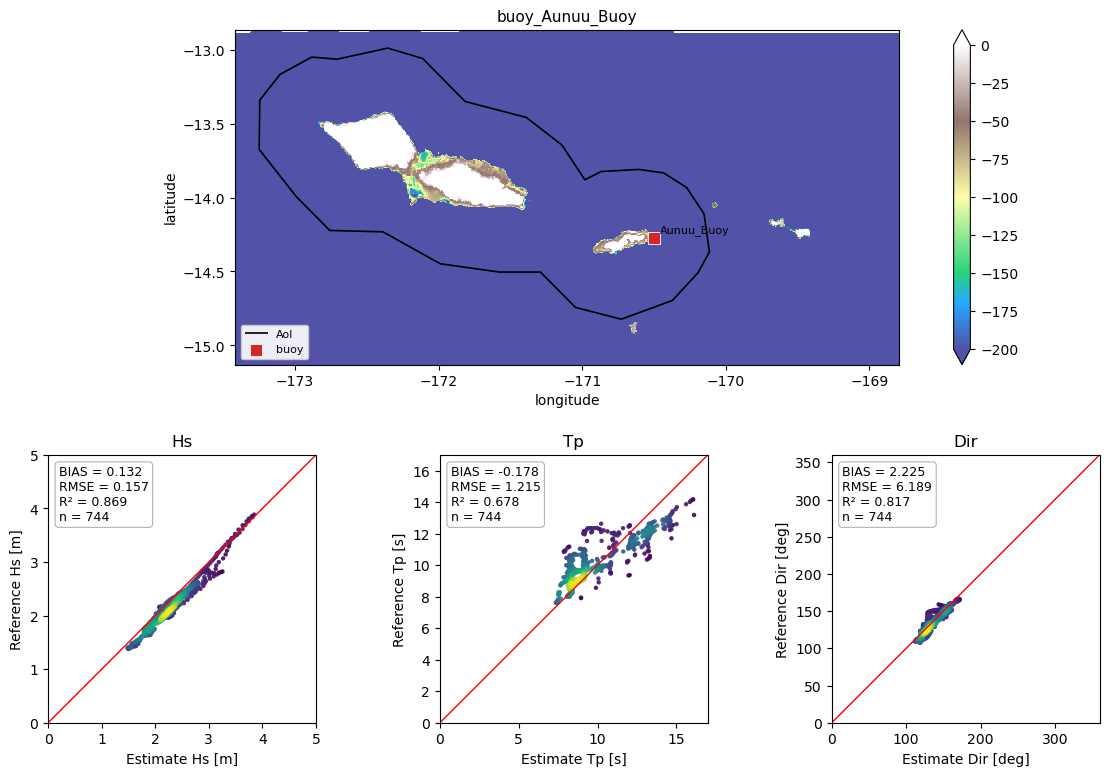

In [8]:
result.plot_all()
plt.show()